In [1]:
%matplotlib inline                                                                                                                                                                 
import pandas as pd                                                                                                                                                                
import numpy as np                                                                                                                                                               
from pathlib import Path                                                                                                                                                           
import networkx as nx                                                                                                                                                            
import matplotlib.pyplot as plt                                                                                                                                                  
from matplotlib.patches import Patch

In [2]:
import os
from dotenv import load_dotenv

load_dotenv(os.path.join(os.path.dirname(os.getcwd()), '.env'))
print(f"HF_TOKEN loaded: {'yes' if os.getenv('HF_TOKEN') else 'no'}")

HF_TOKEN loaded: yes


In [3]:
network_analysis = pd.read_csv("knownWeibos_zg.csv")
network_analysis.head(10)
network_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 167977 entries, 0 to 167976
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   account_id      167977 non-null  int64  
 1   status          164858 non-null  str    
 2   date            167971 non-null  str    
 3   attached_url    56320 non-null   str    
 4   num_likes       56110 non-null   float64
 5   num_comments    56110 non-null   float64
 6   num_forwards    56110 non-null   float64
 7   forwarded       167977 non-null  bool   
 8   f_text          89234 non-null   str    
 9   f_date          89298 non-null   str    
 10  f_post_id       89298 non-null   float64
 11  f_num_comments  83367 non-null   float64
 12  f_num_likes     54387 non-null   float64
 13  f_num_forwards  89254 non-null   float64
 14  f_account_id    89298 non-null   float64
 15  Category        498 non-null     str    
 16  combineposts    167504 non-null  str    
 17  textseg         16797

In [4]:
print(network_analysis.shape)

(167977, 20)


In [5]:
print(network_analysis.columns.tolist())

['account_id', 'status', 'date', 'attached_url', 'num_likes', 'num_comments', 'num_forwards', 'forwarded', 'f_text', 'f_date', 'f_post_id', 'f_num_comments', 'f_num_likes', 'f_num_forwards', 'f_account_id', 'Category', 'combineposts', 'textseg', 'exclusive', 'datecreated']


Nodes = Every unique account_id: 25978
Edges = Every forward relationship: 39436
Network density: 5.84383777102098e-05
Top 10 most forwarded accounts:
 [(3817381137.0, 218), (2643357483.0, 198), (1991123083.0, 156), (2247798535.0, 118), (1844822157.0, 115), (1890254234.0, 103), (2656274875.0, 87), (3880516376.0, 87), (2636715591.0, 84), (3117135703.0, 80)]


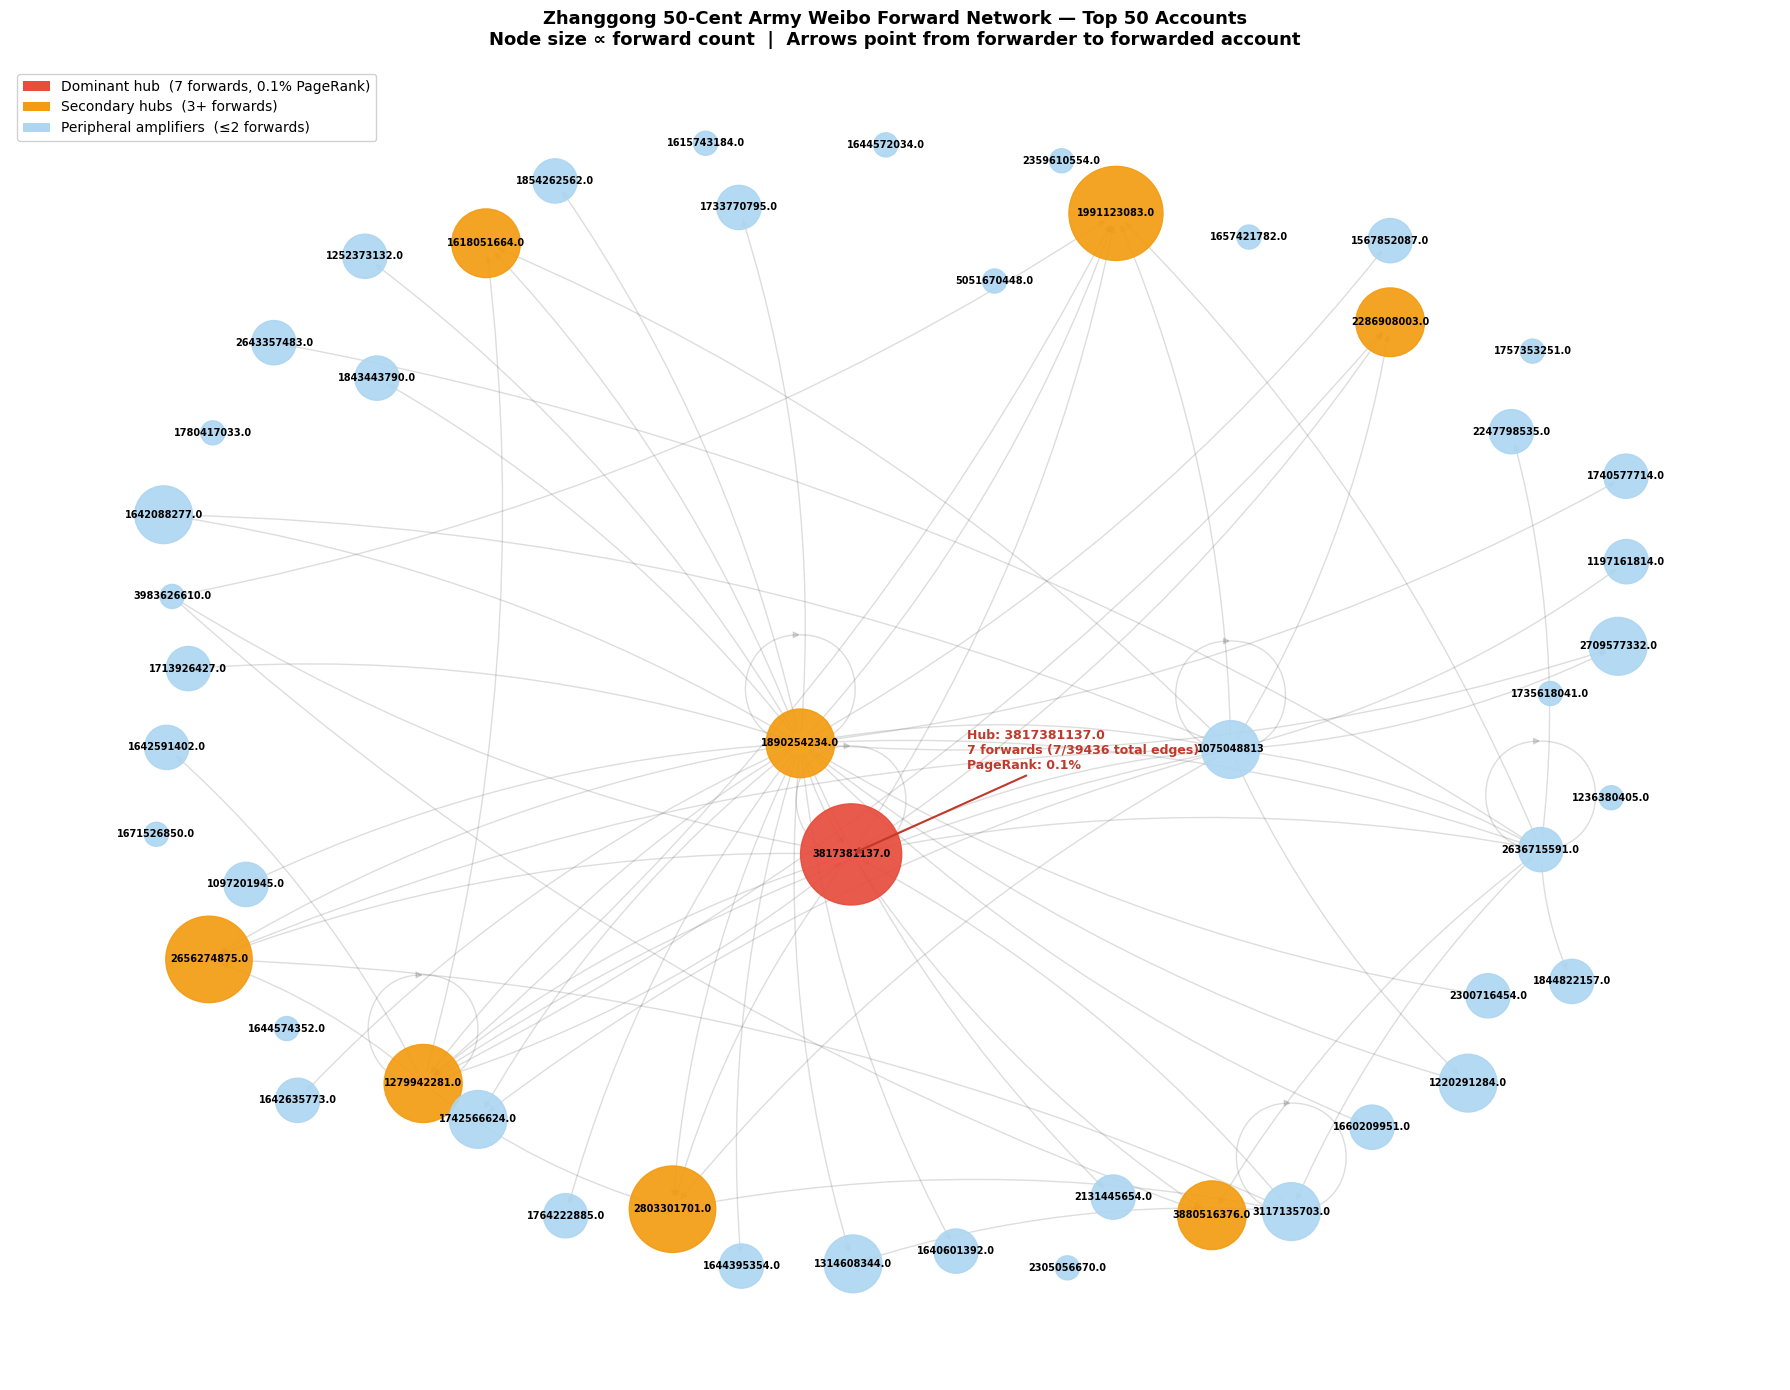

In [6]:
# Filter to forwarded posts only (equivalent to retweets)
forwards = network_analysis[
    network_analysis['forwarded']
].dropna(subset=['account_id', 'f_account_id'])

G = nx.from_pandas_edgelist(
    forwards,
    source='account_id',
    target='f_account_id',
    create_using=nx.DiGraph()
)

print(f"Nodes = Every unique account_id: {G.number_of_nodes()}")
print(f"Edges = Every forward relationship: {G.number_of_edges()}")

in_degrees = dict(G.in_degree())
pageranks = nx.pagerank(G)

print(f"Network density: {nx.density(G)}")
print(f"Top 10 most forwarded accounts:\n {sorted(in_degrees.items(), key=lambda x: x[1], reverse=True)[:10]}")

# Subgraph: top 50 nodes by in-degree only
top_n = 50
top_nodes = sorted(in_degrees, key=in_degrees.get, reverse=True)[:top_n]
G_sub = G.subgraph(top_nodes).copy()

in_deg_sub = dict(G_sub.in_degree())
max_in = max(in_deg_sub.values())

def node_tier(n):
    if in_deg_sub[n] == max_in:
        return '#e74c3c'   # dominant hub
    elif in_deg_sub[n] >= 3:
        return '#f39c12'   # secondary hubs
    else:
        return '#aed6f1'   # peripheral amplifiers

node_colors = [node_tier(n) for n in G_sub.nodes()]
node_sizes  = [300 + (in_deg_sub[n] / max_in) * 5000 for n in G_sub.nodes()]
labels      = {n: str(n) for n in G_sub.nodes()}

plt.figure(figsize=(18, 14))
pos = nx.spring_layout(G_sub, seed=42, k=1.8)

nx.draw_networkx_nodes(G_sub, pos, node_size=node_sizes, node_color=node_colors, alpha=0.92)
nx.draw_networkx_labels(G_sub, pos, labels=labels, font_size=7, font_weight='bold')
nx.draw_networkx_edges(
    G_sub, pos,
    alpha=0.2,
    arrows=True,
    arrowsize=10,
    edge_color='#555555',
    connectionstyle='arc3,rad=0.1'
)

hub = max(in_deg_sub, key=in_deg_sub.get)
hub_pr = round(pageranks[hub] * 100, 1)
hub_rt = in_deg_sub[hub]
plt.annotate(
    f"Hub: {hub}\n{hub_rt} forwards ({hub_rt}/{G.number_of_edges()} total edges)\nPageRank: {hub_pr}%",
    xy=pos[hub], xytext=(pos[hub][0] + 0.15, pos[hub][1] + 0.15),
    fontsize=9, color='#c0392b', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.5)
)

legend_elements = [
    Patch(facecolor='#e74c3c', label=f'Dominant hub  ({hub_rt} forwards, {hub_pr}% PageRank)'),
    Patch(facecolor='#f39c12', label='Secondary hubs  (3+ forwards)'),
    Patch(facecolor='#aed6f1', label='Peripheral amplifiers  (≤2 forwards)'),
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=10, framealpha=0.9)

plt.title(
    f"Zhanggong 50-Cent Army Weibo Forward Network — Top {top_n} Accounts\n"
    "Node size ∝ forward count  |  Arrows point from forwarder to forwarded account",
    fontsize=13, fontweight='bold', pad=16
)
plt.axis('off')
plt.tight_layout()
plt.show()


In [7]:
specific_account = network_analysis[network_analysis['account_id'] == 3817381137]
specific_account

,account_id,status,date,attached_url,num_likes,num_comments,num_forwards,forwarded,f_text,f_date,f_post_id,f_num_comments,f_num_likes,f_num_forwards,f_account_id,Category,combineposts,textseg,exclusive,datecreated
154691,3817381137,此刻，无论你在哪，请为地震遇难同胞默哀3分钟!,2014-08-10 10:03,NaN,0.0,2.0,2.0,True,【此刻，无论你在哪，请为地震遇难同胞默哀3分钟】8月3日16时30分，云南鲁甸发生6.5级地...,2014-8-10 09:58,3.741958e+15,5989.0,9366.0,85547.0,2.656275e+09,NaN,此刻，无论你在哪，请为地震遇难同胞默哀3分钟! 【此刻，无论你在哪，请为地震遇难同胞默哀3分...,此刻 ， 无论 你 在哪 ， 请 为 地震 遇难 同胞 默哀 3 分钟 ! 【 此刻 ， ...,0,2013-09-26
154692,3817381137,转发微博,2013-10-16 08:00,NaN,0.0,0.0,1.0,True,【微倡议：今天是#世界粮食日# 杜绝浪费从我做起】这张照片告诉我们什么是“粒粒皆辛苦”。唤起...,2013-10-16 07:54,3.633936e+15,1999.0,1755.0,15709.0,2.803302e+09,NaN,转发微博 【微倡议：今天是#世界粮食日# 杜绝浪费从我做起】这张照片告诉我们什么是“粒粒皆辛...,转发 微 博 【 微 倡议 ： 今天 是 # 世界 粮食日 # 杜绝 浪费 从我做起 】 ...,0,2013-09-26
154693,3817381137,#赣南苏区振兴发展图片展# 花絮：今天来到北京展览馆观展的观众好有口福哦！既可以欣赏到客家新...,2015-01-11 11:27,NaN,5.0,3.0,2.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#赣南苏区振兴发展图片展# 花絮：今天来到北京展览馆观展的观众好有口福哦！既可以欣赏到客家新...,# 赣南 苏区 振兴 发展 图片展 # 花絮 ： 今天 来到 北京 展览馆 观展 的 观众 ...,0,2013-09-26
154694,3817381137,【我省多措并举优化服务 赣台会36个签约项目进资】截至1月9日，第十一届赣台会上签约的75个...,2014-01-13 09:17,http://t.cn/8F2h2J7,1.0,0.0,1.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,【我省多措并举优化服务 赣台会36个签约项目进资】截至1月9日，第十一届赣台会上签约的75个...,【 我 省 多措 并举 优化 服务 赣台 会 36 个 签约 项目 进 资 】 截至 1月...,0,2013-09-26
154695,3817381137,#苏区振兴·三年大变样# 【赣州转型升级 “聚变”出彩】三年，围绕建设全国稀有金属产业基地、...,2015-06-28 13:38,NaN,28.0,150.0,45.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#苏区振兴·三年大变样# 【赣州转型升级 “聚变”出彩】三年，围绕建设全国稀有金属产业基地、...,# 苏区 振兴 · 三 年 大 变样 # 【 赣州 转型 升级 “ 聚变 ” 出彩 】 三 ...,0,2013-09-26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161342,3817381137,【黄金机场改扩建环评报告获批】#赣州新闻# 赣州黄金机场改扩建工程项目环境影响报告书获得江西...,2014-11-06 16:36,javascript:void(0),4.0,0.0,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,【黄金机场改扩建环评报告获批】#赣州新闻# 赣州黄金机场改扩建工程项目环境影响报告书获得江西...,【 黄金 机场 改扩建 环评 报告 获批 】 # 赣州 新闻 # 赣州 黄金 机场 改扩建...,0,2013-09-26
161343,3817381137,NaN,2014-03-02 22:35,NaN,0.0,0.0,0.0,True,【此刻，请为无辜殒命的同胞点起】昨天，3月1日21时许，昆明发生暴力恐怖袭击事件，29人死亡...,2014-3-2 17:12,3.683723e+15,1027.0,46322.0,244533.0,2.656275e+09,NaN,【此刻，请为无辜殒命的同胞点起】昨天，3月1日21时许，昆明发生暴力恐怖袭击事件，29人死...,【 此刻 ， 请 为 无辜 殒命 的 同胞 点 起 】 昨天 ， 3月 1日 21 时许 ...,0,2013-09-26
161344,3817381137,#《若干意见》出台两周年# 冷新生说，《若干意见》出台实施两年来，赣州全市上下感恩奋进，抢抓...,2014-06-24 08:21,NaN,0.0,0.0,3.0,True,【赣南苏区振兴发展取得重大阶段性成效】#《若干意见》出台两周年# 6月23日，我市召开《国务...,2014-6-24 08:21,3.724902e+15,2.0,1.0,11.0,3.817381e+09,NaN,#《若干意见》出台两周年# 冷新生说，《若干意见》出台实施两年来，赣州全市上下感恩奋进，抢抓...,# 《 若干 意见 》 出台 两 周年 # 冷 新生 说 ， 《 若干 意见 》 出台 实施...,0,2013-09-26
161345,3817381137,【中央媒体聚焦赣县教育实践活动】6月23日，人民日报、新华社、光明日报、经济日报等中央媒体聚...,2014-06-24 08:15,http://t.cn/Rvjltwh,0.0,1.0,2.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,【中央媒体聚焦赣县教育实践活动】6月23日，人民日报、新华社、光明日报、经济日报等中央媒体聚...,【 中央 媒体 聚焦 赣县 教育 实践 活动 】 6月 23日 ， 人民 日报 、 新华社...,0,2013-09-26


Inbound forwards (others → this account): 2509
Outbound forwards (this account → others): 1430
In-degree (times forwarded): 218
Out-degree (accounts it forwards): 230
PageRank: 0.001357
Ego network — Nodes: 230, Edges: 268
Ego network density: 0.0051


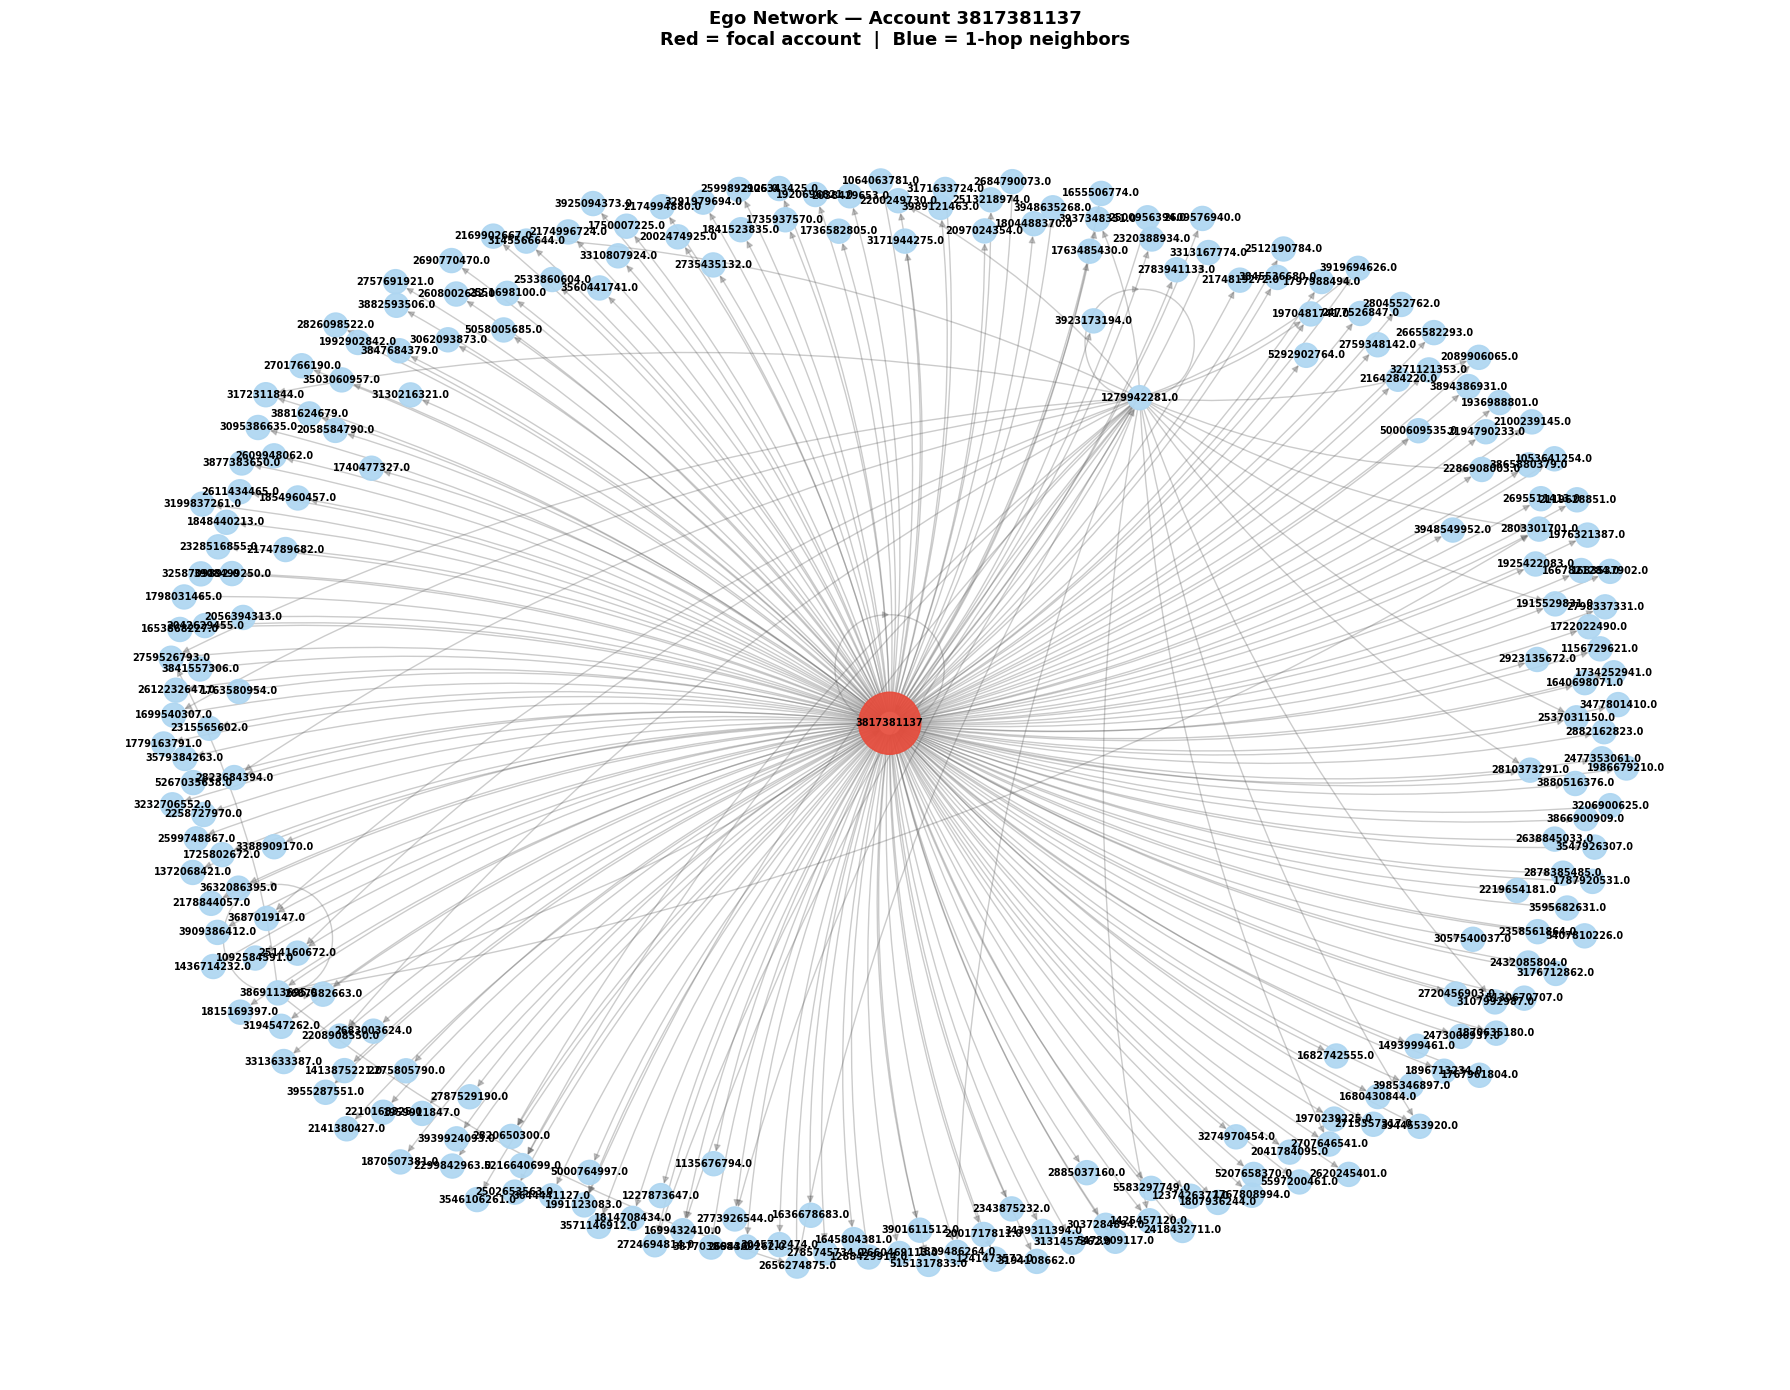

In [8]:
account_id = 3817381137

# Build ego network FIRST (was defined after use — this caused the bug)
ego = nx.ego_graph(G, account_id, radius=1)

# Who forwards this account
inbound = forwards[forwards['f_account_id'] == account_id]
# What this account forwards
outbound = forwards[forwards['account_id'] == account_id]

print(f"Inbound forwards (others → this account): {len(inbound)}")
print(f"Outbound forwards (this account → others): {len(outbound)}")
print(f"In-degree (times forwarded): {G.in_degree(account_id)}")
print(f"Out-degree (accounts it forwards): {G.out_degree(account_id)}")
print(f"PageRank: {pageranks[account_id]:.6f}")
print(f"Ego network — Nodes: {ego.number_of_nodes()}, Edges: {ego.number_of_edges()}")
print(f"Ego network density: {nx.density(ego):.4f}")

in_deg_ego = dict(ego.in_degree())
node_colors_ego = ['#e74c3c' if n == account_id else '#aed6f1' for n in ego.nodes()]
node_sizes_ego  = [2000 if n == account_id else 300 for n in ego.nodes()]

plt.figure(figsize=(18, 14))
pos_ego = nx.spring_layout(ego, seed=42, k=1.8)

nx.draw_networkx_nodes(ego, pos_ego, node_size=node_sizes_ego,
                       node_color=node_colors_ego, alpha=0.92)
nx.draw_networkx_labels(ego, pos_ego, font_size=7, font_weight='bold')
nx.draw_networkx_edges(ego, pos_ego, alpha=0.3, arrows=True,
                       arrowsize=10, edge_color='#555555',
                       connectionstyle='arc3,rad=0.1')

plt.title(
    f"Ego Network — Account {account_id}\n"
    "Red = focal account  |  Blue = 1-hop neighbors",
    fontsize=13, fontweight='bold', pad=16
)
plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
from transformers import pipeline

# Scope to posts from top 50 accounts only — avoids running on all 167K rows
top_posts = network_analysis[
    network_analysis['account_id'].isin(top_nodes)
].dropna(subset=['f_text']).copy()

print(f"Posts to score: {len(top_posts)}")

# Multilingual model — runs directly on Chinese, no translation needed
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    truncation=True,
    max_length=512
)

def get_sentiment(text):
    if pd.isna(text) or not str(text).strip():
        return None, None
    result = sentiment_pipeline(str(text)[:512])[0]
    return result['label'], result['score']

top_posts[['sentiment', 'sentiment_score']] = top_posts['f_text'].apply(
    lambda x: pd.Series(get_sentiment(x))
)

print(top_posts['sentiment'].value_counts())


Posts to score: 4145


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

sentiment
positive    2756
negative    1280
neutral      109
Name: count, dtype: int64


In [10]:
# Aggregate sentiment per account — map to -1/0/+1 then average
def sentiment_value(label, score):
    if label == 'positive':
        return score
    elif label == 'negative':
        return -score
    return 0.0

top_posts['sentiment_value'] = top_posts.apply(
    lambda r: sentiment_value(r['sentiment'], r['sentiment_score']), axis=1
)

account_sentiment = (
    top_posts.groupby('account_id')['sentiment_value']
    .mean()
    .to_dict()
)

print("Account sentiment scores (sample):")
for acct, val in sorted(account_sentiment.items(), key=lambda x: x[1])[:5]:
    print(f"  {acct}: {val:.3f}")
print("  ...")
for acct, val in sorted(account_sentiment.items(), key=lambda x: x[1])[-5:]:
    print(f"  {acct}: {val:.3f}")


Account sentiment scores (sample):
  1279942281: 0.016
  1890254234: 0.191
  1075048813: 0.223
  3117135703: 0.337
  2643357483: 0.401
  ...
  3117135703: 0.337
  2643357483: 0.401
  3817381137: 0.465
  2636715591: 0.585
  3983626610: 0.635


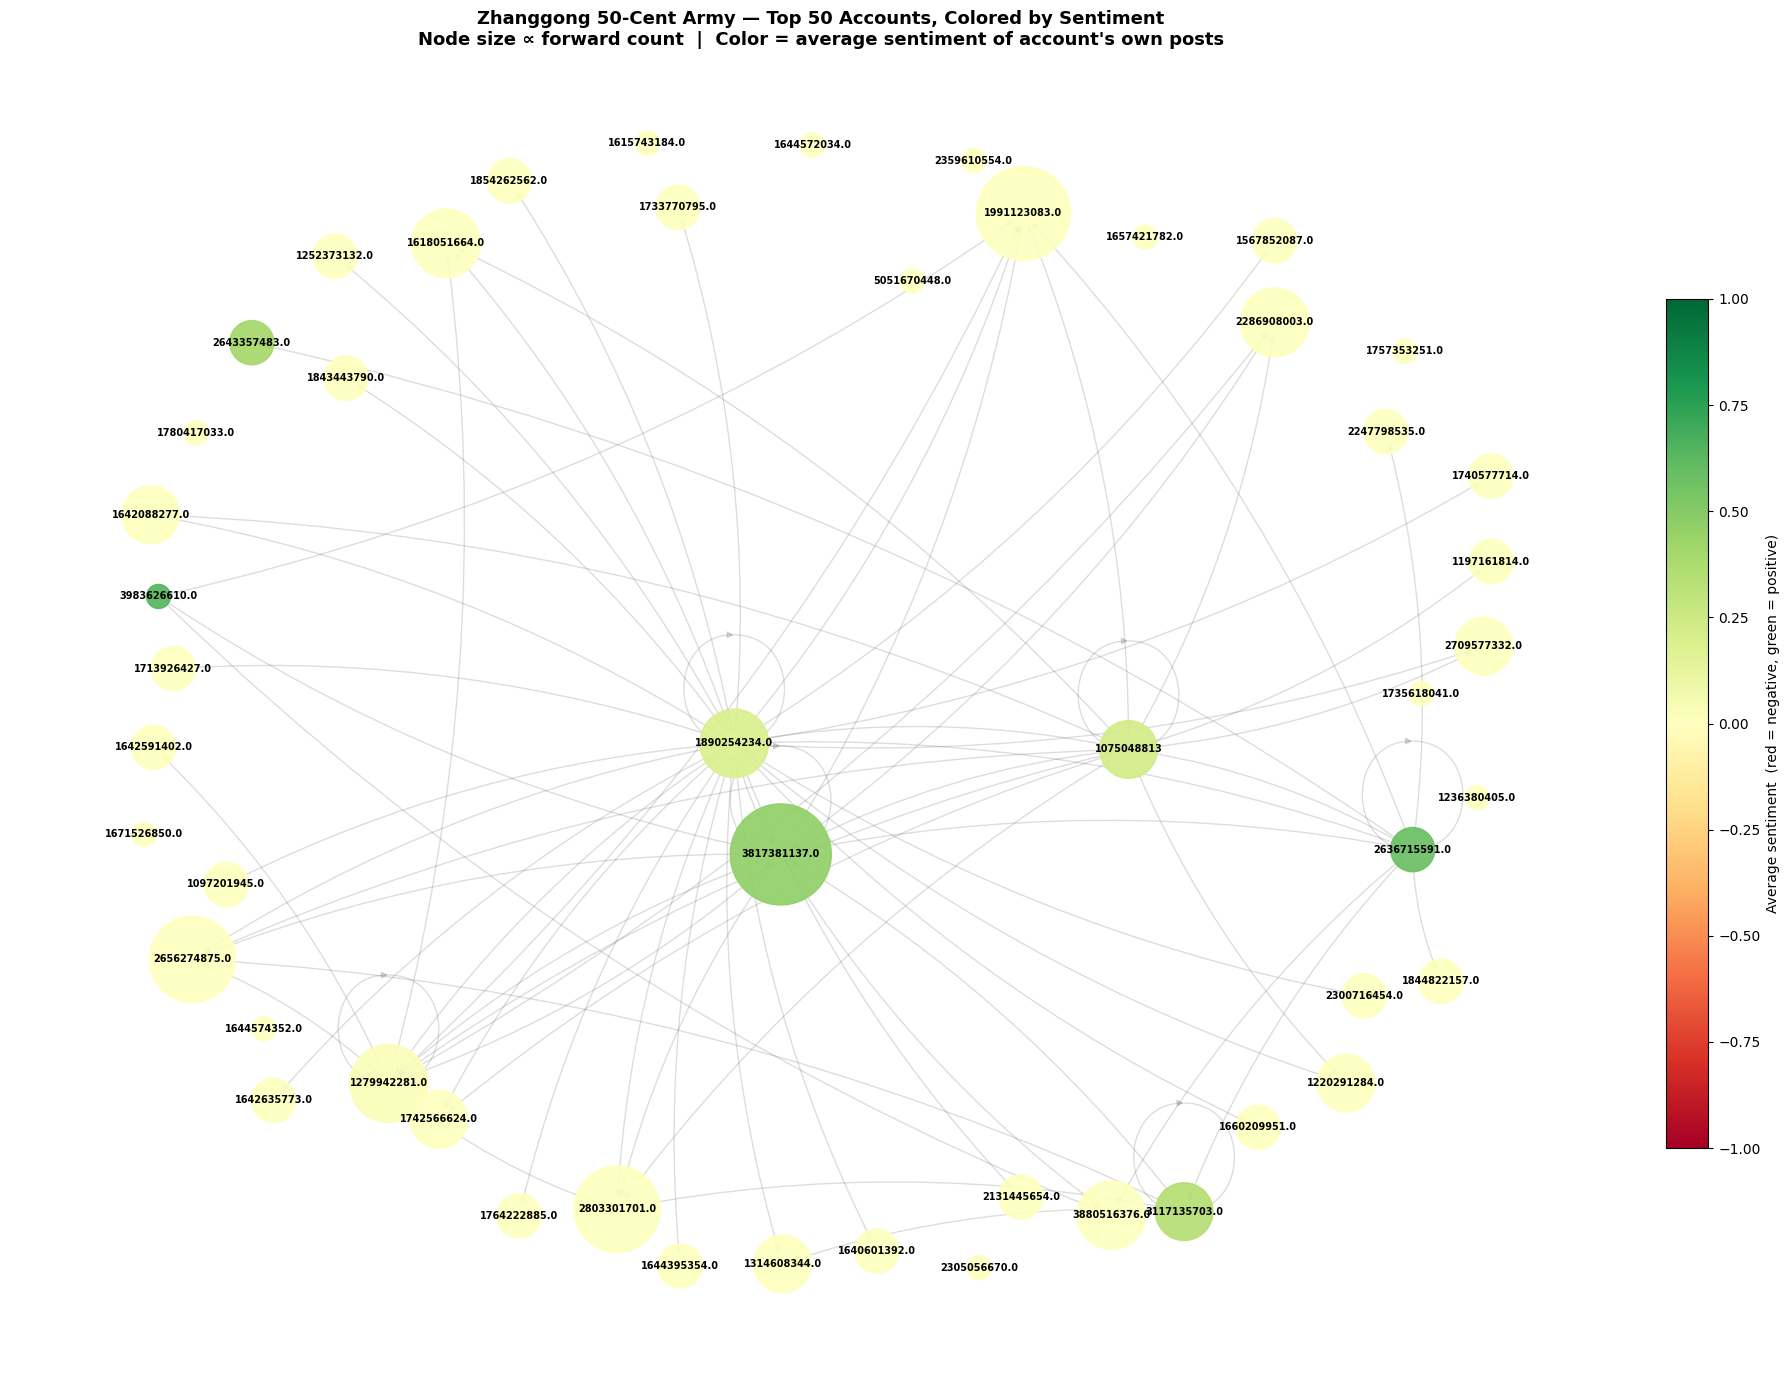

In [11]:
import matplotlib.cm as cm

cmap = plt.cm.RdYlGn
norm = plt.Normalize(vmin=-1, vmax=1)

# Fallback to 0 (neutral) for any node missing sentiment data
node_sentiment = [account_sentiment.get(n, 0.0) for n in G_sub.nodes()]
node_colors_sentiment = [cmap(norm(s)) for s in node_sentiment]
node_sizes_sentiment  = [300 + (in_deg_sub[n] / max_in) * 5000 for n in G_sub.nodes()]

plt.figure(figsize=(18, 14))
pos = nx.spring_layout(G_sub, seed=42, k=1.8)

sc = nx.draw_networkx_nodes(
    G_sub, pos,
    node_size=node_sizes_sentiment,
    node_color=node_colors_sentiment,
    alpha=0.92
)
nx.draw_networkx_labels(G_sub, pos, font_size=7, font_weight='bold')
nx.draw_networkx_edges(
    G_sub, pos,
    alpha=0.2,
    arrows=True,
    arrowsize=10,
    edge_color='#555555',
    connectionstyle='arc3,rad=0.1'
)

# Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=plt.gca(), orientation='vertical', fraction=0.025, pad=0.02,
             label='Average sentiment  (red = negative, green = positive)')

plt.title(
    f"Zhanggong 50-Cent Army — Top {top_n} Accounts, Colored by Sentiment\n"
    "Node size ∝ forward count  |  Color = average sentiment of account's own posts",
    fontsize=13, fontweight='bold', pad=16
)
plt.axis('off')
plt.tight_layout()
plt.show()


Accounts with both network + sentiment data: 8
        in_degree  pagerank  sentiment_value
count    8.000000  8.000000         8.000000
mean   109.000000  0.000700         0.356598
std     63.023805  0.000457         0.208760
min     53.000000  0.000262         0.015916
25%     68.500000  0.000414         0.214765
50%     82.000000  0.000493         0.368970
75%    126.750000  0.000896         0.495368
max    218.000000  0.001454         0.634512

                            OLS Regression Results                            
Dep. Variable:        sentiment_value   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                 -0.085
Method:                 Least Squares   F-statistic:                    0.4526
Date:                Tue, 04 Aug 2026   Prob (F-statistic):              0.526
Time:                        14:41:55   Log-Likelihood:                 2.0061
No. Observations:                   8   AIC:                          -0.

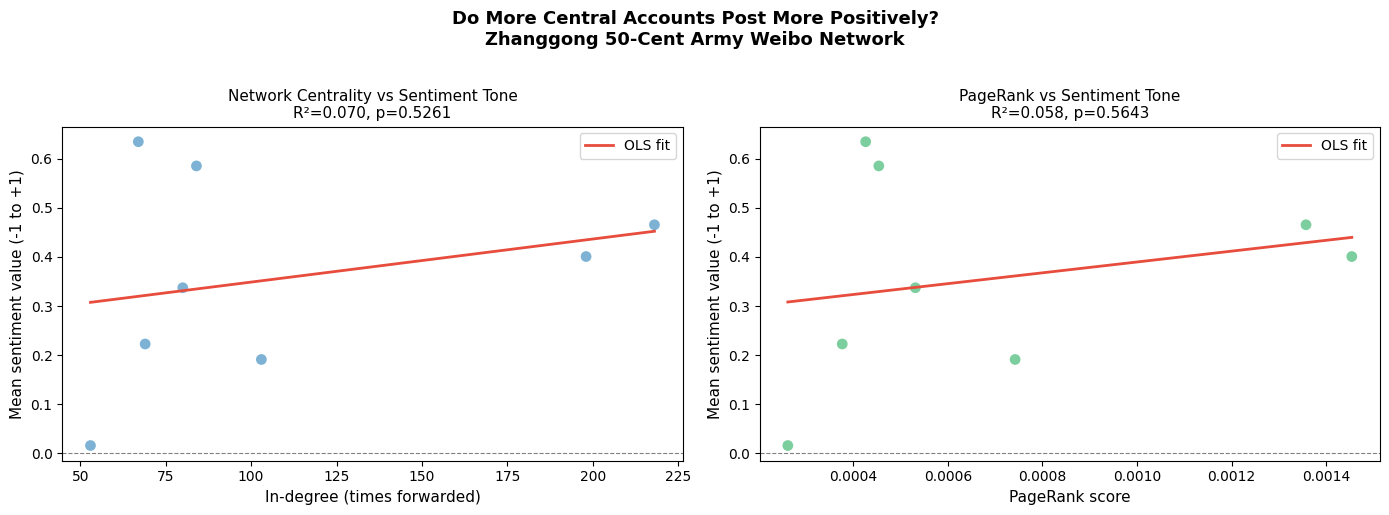


INTERPRETATION:
  A positive coefficient on in_degree means more-forwarded accounts
  post more positively — consistent with strategic hub-driven narrative
  amplification rather than organic discussion.
  A non-significant result means sentiment is evenly distributed
  regardless of network position.


In [12]:
# Does network influence predict sentiment tone?
#
# Research question: Do more central accounts (higher in-degree / PageRank)
# post more positively? If yes, it suggests the network structure is being
# used to strategically amplify positive CCP narratives, not just any content.
#
# Model: sentiment_value ~ in_degree  (OLS regression)
# The ~ syntax is from statsmodels formula API, equivalent to R's lm()

import statsmodels.formula.api as smf
import scipy.stats as stats

# Build a dataframe with one row per account that has both
# network metrics and sentiment scores
account_df = pd.DataFrame({
    'account_id':     list(in_degrees.keys()),
    'in_degree':      list(in_degrees.values()),
    'pagerank':       [pageranks[n] for n in in_degrees.keys()],
}).set_index('account_id')

# Merge in sentiment scores — only accounts with both metrics
account_df['sentiment_value'] = account_df.index.map(account_sentiment)
account_df = account_df.dropna(subset=['sentiment_value'])

print(f"Accounts with both network + sentiment data: {len(account_df)}")
print(account_df.describe())
print()

# --- OLS Regression: sentiment_value ~ in_degree ---
# The ~ is statsmodels formula syntax:
#   left of ~ is the dependent variable (what you're predicting)
#   right of ~ is the independent variable (the predictor)

model = smf.ols('sentiment_value ~ in_degree', data=account_df).fit()
print(model.summary())

# --- Spearman correlation (non-parametric, better for skewed degree distributions) ---
rho, p_spearman = stats.spearmanr(account_df['in_degree'],
                                   account_df['sentiment_value'])
print(f"\nSpearman correlation (in_degree vs sentiment): rho={rho:.4f}, p={p_spearman:.4f}")

# --- Scatter plot with regression line ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: in_degree vs sentiment
ax = axes[0]
ax.scatter(account_df['in_degree'], account_df['sentiment_value'],
           alpha=0.6, s=60, color='#2980b9', edgecolors='none')

# Add regression line
x_range = np.linspace(account_df['in_degree'].min(),
                      account_df['in_degree'].max(), 100)
y_pred = model.params['Intercept'] + model.params['in_degree'] * x_range
ax.plot(x_range, y_pred, color='#e74c3c', linewidth=2, label='OLS fit')
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

r2 = model.rsquared
p_val = model.pvalues['in_degree']
ax.set_xlabel('In-degree (times forwarded)', fontsize=11)
ax.set_ylabel('Mean sentiment value (-1 to +1)', fontsize=11)
ax.set_title(f'Network Centrality vs Sentiment Tone\n'
             f'R²={r2:.3f}, p={p_val:.4f}', fontsize=11)
ax.legend()

# Plot 2: PageRank vs sentiment (PageRank is more robust than raw in-degree)
ax2 = axes[1]
ax2.scatter(account_df['pagerank'], account_df['sentiment_value'],
            alpha=0.6, s=60, color='#27ae60', edgecolors='none')

model_pr = smf.ols('sentiment_value ~ pagerank', data=account_df).fit()
x_pr = np.linspace(account_df['pagerank'].min(),
                   account_df['pagerank'].max(), 100)
y_pr = model_pr.params['Intercept'] + model_pr.params['pagerank'] * x_pr
ax2.plot(x_pr, y_pr, color='#e74c3c', linewidth=2, label='OLS fit')
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8)

r2_pr = model_pr.rsquared
p_pr = model_pr.pvalues['pagerank']
ax2.set_xlabel('PageRank score', fontsize=11)
ax2.set_ylabel('Mean sentiment value (-1 to +1)', fontsize=11)
ax2.set_title(f'PageRank vs Sentiment Tone\n'
              f'R²={r2_pr:.3f}, p={p_pr:.4f}', fontsize=11)
ax2.legend()

plt.suptitle('Do More Central Accounts Post More Positively?\n'
             'Zhanggong 50-Cent Army Weibo Network',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- Interpretation guidance ---
print("\nINTERPRETATION:")
print("  A positive coefficient on in_degree means more-forwarded accounts")
print("  post more positively — consistent with strategic hub-driven narrative")
print("  amplification rather than organic discussion.")
print("  A non-significant result means sentiment is evenly distributed")
print("  regardless of network position.")